In [1]:
# Load Libraries
import pandas as pd      
import numpy as np            
import matplotlib.pyplot as plt     
import seaborn as sns 

In [ ]:
# Load the data 
""" Start with Loading the data, multiple data types but start
    with .csv file
"""

df = pd.read_csv("sample_drone_flights.csv")

# inspect the first 5 columns 
# drone data with multiple columns 
df.head(5)

,time(millisecond),datetime(utc),latitude,longitude,height_above_takeoff(feet),height_above_ground_at_drone_location(feet),ground_elevation_at_drone_location(feet),altitude_above_seaLevel(feet),height_sonar(feet),speed(mph),...,voltageCell4,voltageCell5,voltageCell6,current(A),battery_temperature(f),altitude(feet),ascent(feet),flycStateRaw,flycState,message
0,4820,2019-05-17 15:08:13,38.127558,-84.510858,7.545932,7.545932,873.747926,881.293858,0,-0.600001,...,NaN,NaN,NaN,14.714,35.95001,881.293858,7.545932,14,Waypoint,Mission did take off
1,4920,2019-05-17 15:08:13,38.127558,-84.510858,7.545932,7.545932,873.747926,881.293858,0,-0.600001,...,NaN,NaN,NaN,14.714,35.95001,881.293858,7.545932,14,Waypoint,NaN
2,5020,2019-05-17 15:08:13,38.127558,-84.510857,7.874016,7.874016,873.747926,881.621942,0,-0.600001,...,NaN,NaN,NaN,14.714,35.95001,881.621942,7.874016,14,Waypoint,NaN
3,5120,2019-05-17 15:08:13,38.127558,-84.510857,8.202100,8.202100,873.747926,881.950026,0,-0.800001,...,NaN,NaN,NaN,14.714,35.95001,881.950026,8.202100,14,Waypoint,NaN
4,5220,2019-05-17 15:08:13,38.127558,-84.510857,8.530184,8.530184,873.747926,882.278110,0,-1.000002,...,NaN,NaN,NaN,14.714,35.95001,882.278110,8.530184,14,Waypoint,NaN


In [ ]:
# view columns 
print(len(df.columns))


54


In [11]:
# clean up column names 
df.columns = (df.columns.
                str.lower().
                str.strip().
                str.replace("(" ," ").
                str.replace(" ", "_").
                str.replace(")", " ").
                str.strip()
                )
df.columns

Index(['time_millisecond', 'datetime_utc', 'latitude', 'longitude',
       'height_above_takeoff_feet',
       'height_above_ground_at_drone_location_feet',
       'ground_elevation_at_drone_location_feet',
       'altitude_above_sealevel_feet', 'height_sonar_feet', 'speed_mph',
       'distance_feet', 'mileage_feet', 'satellites', 'gpslevel', 'voltage_v',
       'max_altitude_feet', 'max_ascent_feet', 'max_speed_mph',
       'max_distance_feet', 'xspeed_mph', 'yspeed_mph', 'zspeed_mph',
       'compass_heading_degrees', 'pitch_degrees', 'roll_degrees',
       'wind_speed_mph', 'wind_direction_degrees', 'isphoto', 'isvideo',
       'rc_elevator', 'rc_aileron', 'rc_throttle', 'rc_rudder',
       'rc_elevator_percent', 'rc_aileron_percent', 'rc_throttle_percent',
       'rc_rudder_percent', 'gimbal_heading_degrees', 'gimbal_pitch_degrees',
       'gimbal_roll_degrees', 'battery_percent', 'voltagecell1',
       'voltagecell2', 'voltagecell3', 'voltagecell4', 'voltagecell5',
       'voltag

In [14]:
# Date Handleing 
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
              

In [15]:
df.head()

,time_millisecond,datetime_utc,latitude,longitude,height_above_takeoff_feet,height_above_ground_at_drone_location_feet,ground_elevation_at_drone_location_feet,altitude_above_sealevel_feet,height_sonar_feet,speed_mph,...,voltagecell4,voltagecell5,voltagecell6,current_a,battery_temperature_f,altitude_feet,ascent_feet,flycstateraw,flycstate,message
0,4820,2019-05-17 15:08:13,38.127558,-84.510858,7.545932,7.545932,873.747926,881.293858,0,-0.600001,...,NaN,NaN,NaN,14.714,35.95001,881.293858,7.545932,14,Waypoint,Mission did take off
1,4920,2019-05-17 15:08:13,38.127558,-84.510858,7.545932,7.545932,873.747926,881.293858,0,-0.600001,...,NaN,NaN,NaN,14.714,35.95001,881.293858,7.545932,14,Waypoint,NaN
2,5020,2019-05-17 15:08:13,38.127558,-84.510857,7.874016,7.874016,873.747926,881.621942,0,-0.600001,...,NaN,NaN,NaN,14.714,35.95001,881.621942,7.874016,14,Waypoint,NaN
3,5120,2019-05-17 15:08:13,38.127558,-84.510857,8.202100,8.202100,873.747926,881.950026,0,-0.800001,...,NaN,NaN,NaN,14.714,35.95001,881.950026,8.202100,14,Waypoint,NaN
4,5220,2019-05-17 15:08:13,38.127558,-84.510857,8.530184,8.530184,873.747926,882.278110,0,-1.000002,...,NaN,NaN,NaN,14.714,35.95001,882.278110,8.530184,14,Waypoint,NaN


In [16]:
df["wind_speed_mph"].unique()

<StringArray>
['Available with Enterprise subscription', nan]
Length: 2, dtype: str

In [32]:
dropped_cols = [
    "time_millisecond",
    "wind_speed_mph",
    "wind_direction_degrees",
    "isvideo",
    "isphoto",
    "voltagecell1",
    "voltagecell2",
    "voltagecell3",
    "voltagecell4",
    "voltagecell5",
    "voltagecell6",
    "message", 
    # "flycstate", 
]

df_new = df.drop(columns=dropped_cols)

In [34]:
df_new.select_dtypes(include="number").describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,9616.0,38.127872,0.000315,38.127357,38.127570,38.127854,38.128113,38.128588
longitude,9616.0,-84.510271,0.000412,-84.511092,-84.510573,-84.510309,-84.509959,-84.509314
height_above_takeoff_feet,9616.0,68.723465,10.323273,5.905512,69.553808,69.881892,70.209976,93.175856
height_above_ground_at_drone_location_feet,9616.0,69.358534,10.610852,4.757218,69.619425,70.341210,72.408139,93.471132
ground_elevation_at_drone_location_feet,9616.0,873.112857,1.825918,870.467086,871.615380,873.518267,873.747926,879.292546
altitude_above_sealevel_feet,9616.0,942.471391,10.323273,879.653438,943.301734,943.629818,943.957902,966.923782
height_sonar_feet,9616.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
speed_mph,9616.0,0.000291,0.371757,-3.000005,0.000000,0.000000,0.000000,4.000007
distance_feet,9616.0,242.279705,100.564465,0.000000,159.298069,248.226878,328.136493,462.109595
mileage_feet,9616.0,3125.686944,1803.249886,0.000000,1555.554512,3138.860009,4722.908616,5823.228533


In [36]:
selected_cols = [
    "datetime_utc", 
    "voltage_v",
    "battery_percent", 
    "battery_temperature_f",
    "speed_mph",
    "current_a",
    "flycstate", 
]

df_subset = df_new[selected_cols]

In [37]:
df_subset

,datetime_utc,voltage_v,battery_percent,battery_temperature_f,speed_mph,current_a,flycstate
0,2019-05-17 15:08:13,15.497,88,35.95001,-0.600001,14.714,Waypoint
1,2019-05-17 15:08:13,15.497,88,35.95001,-0.600001,14.714,Waypoint
2,2019-05-17 15:08:13,15.497,88,35.95001,-0.600001,14.714,Waypoint
3,2019-05-17 15:08:13,15.497,88,35.95001,-0.800001,14.714,Waypoint
4,2019-05-17 15:08:13,15.497,88,35.95001,-1.000002,14.714,Waypoint
...,...,...,...,...,...,...,...
9611,2019-05-17 15:24:15,14.371,21,61.95002,0.000000,13.126,Sport
9612,2019-05-17 15:24:15,14.371,21,61.95002,0.000000,13.126,Sport
9613,2019-05-17 15:24:15,14.371,21,61.95002,0.000000,13.126,Sport
9614,2019-05-17 15:24:15,14.371,21,61.95002,0.000000,13.126,Sport


### Slicing Data 

In [38]:
df_subset["flycstate"].unique()

<StringArray>
['Waypoint', 'Sport', 'P-GPS', 'Go_Home']
Length: 4, dtype: str

In [56]:
mapped_state = {
    "Waypoint":"waypoint",
    "Sport":"sports",
    "P-GPS": "pgps",
    "Go_Home":"home_beacon",
}

In [ ]:
# select only specifict flycstate
dfx = df_subset[df_subset["flycstate"].isin(['Sport', 'P-GPS'])]
dfn = df_subset[(df_subset["flycstate"]=="Sport")|
          (df_subset["flycstate"] == "P-GPS")
          ]

print(dfx.shape)
print(dfn.shape)

df_merge = dfx.merge(dfn, 
                    on=selected_cols,
                     )

(1250, 7)
(1250, 7)


In [57]:
dfx["flystate_new"] = dfx["flycstate"].map(mapped_state)

In [58]:
dfx.head()

,datetime_utc,voltage_v,battery_percent,battery_temperature_f,speed_mph,current_a,flycstate,flystate_new
8305,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,Sport,sports
8306,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,Sport,sports
8307,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,Sport,sports
8308,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,Sport,sports
8309,2019-05-17 15:22:04,14.479,30,58.94996,0.1,13.076,Sport,sports


In [59]:
dfx.loc[:, "flycstate"] = dfx["flystate_new"]

In [60]:
dfx.iloc[:, 0:3]

,datetime_utc,voltage_v,battery_percent
8305,2019-05-17 15:22:04,14.479,30
8306,2019-05-17 15:22:04,14.479,30
8307,2019-05-17 15:22:04,14.479,30
8308,2019-05-17 15:22:04,14.479,30
8309,2019-05-17 15:22:04,14.479,30
...,...,...,...
9611,2019-05-17 15:24:15,14.371,21
9612,2019-05-17 15:24:15,14.371,21
9613,2019-05-17 15:24:15,14.371,21
9614,2019-05-17 15:24:15,14.371,21


In [65]:
dfx[dfx["battery_percent"].le(50)]

,datetime_utc,voltage_v,battery_percent,battery_temperature_f,speed_mph,current_a,flycstate,flystate_new
8305,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8306,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8307,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8308,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8309,2019-05-17 15:22:04,14.479,30,58.94996,0.1,13.076,sports,sports
...,...,...,...,...,...,...,...,...
9611,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports
9612,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports
9613,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports
9614,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports


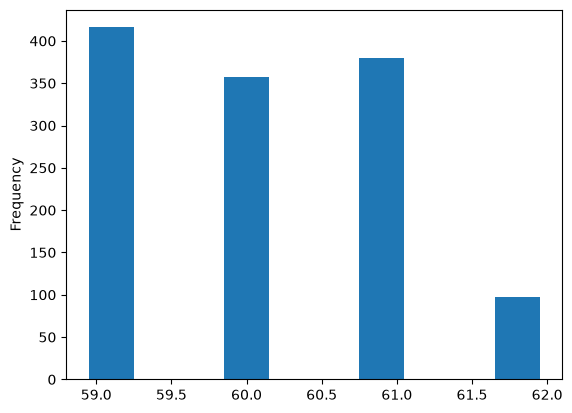

In [85]:
dfx["battery_temperature_f"].plot(kind="hist")
plt.show()

In [70]:
dfx[dfx["speed_mph"].gt(0)]

,datetime_utc,voltage_v,battery_percent,battery_temperature_f,speed_mph,current_a,flycstate,flystate_new
8309,2019-05-17 15:22:04,14.479,30,58.94996,0.1,13.076,sports,sports
8313,2019-05-17 15:22:05,14.452,30,58.94996,0.1,13.076,sports,sports
8335,2019-05-17 15:22:07,14.452,29,58.94996,0.1,13.992,sports,sports
8336,2019-05-17 15:22:07,14.452,29,58.94996,0.1,13.992,sports,sports
8337,2019-05-17 15:22:07,14.452,29,58.94996,0.1,13.992,sports,sports
...,...,...,...,...,...,...,...,...
9599,2019-05-17 15:24:13,14.344,21,61.95002,0.2,13.126,sports,sports
9600,2019-05-17 15:24:14,14.344,21,61.95002,0.2,13.126,sports,sports
9601,2019-05-17 15:24:14,14.344,21,61.95002,0.2,13.126,sports,sports
9602,2019-05-17 15:24:14,14.344,21,61.95002,0.2,13.126,sports,sports


In [84]:
dfx.groupby(["flystate_new"])["battery_temperature_f"].agg(["sum", 
                                                            "min",
                                                            "max",
                                                             "mean",
                                                             "median",
                                                            ])

,sum,min,max,mean,median
flystate_new,,,,,
pgps,24573.29688,58.94996,59.95004,59.35579,58.94996
sports,50522.17990,58.94996,61.95002,60.43323,60.94994


In [87]:
dfx.loc[:, dfx.columns.drop_duplicates()]

,datetime_utc,voltage_v,battery_percent,battery_temperature_f,speed_mph,current_a,flycstate,flystate_new
8305,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8306,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8307,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8308,2019-05-17 15:22:04,14.479,30,58.94996,0.0,13.076,sports,sports
8309,2019-05-17 15:22:04,14.479,30,58.94996,0.1,13.076,sports,sports
...,...,...,...,...,...,...,...,...
9611,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports
9612,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports
9613,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports
9614,2019-05-17 15:24:15,14.371,21,61.95002,0.0,13.126,sports,sports
